# ML-10 — Content Action Playbook

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/m-awaischohan/flyrank-internship-ml/blob/main/work/notebooks/w07_action_playbook.ipynb?flush_cache=true)

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

**What this notebook is.** The Week-5 model ranks pages; this notebook turns that ranking into something a person can use on Monday morning: a ranked review queue where every row says *why* it is there, what a reviewer should check, and when to stop trusting it. It is a **non-production, decision-support playbook** built on one snapshot of the starter file. Nothing here edits a page, and nothing here claims that an action raises clicks.

**Lane 4 reminder:** which visible pages earn a much lower CTR than their position normally earns, *and are likely to stay that way*? The label is a proxy (`low_later`: later-30-day CTR under half of the position band's typical CTR), not an observed result of any fix.

## 1. Ranked actions + reason codes

**How the queue is built (one line each):**
- **Score** = average of the logistic-regression and gradient-boosting probabilities of `low_later` (Week-5 models, same features, same client-grouped folds). I use the average because Week 5 concluded logistic regression is the model I can explain and boosting is the check; averaging keeps both honest voices in the list. Every page is scored **by a model that never saw its client**.
- **Scope guard:** only pages with at least 100 impressions in the earlier 30 days and a real position (1-20). Pages outside that are never scored.
- **Reason codes** are *descriptions of the page* computed from earlier-window numbers, not "why the model decided". They are there so a reviewer can sanity-check a row in ten seconds.
- **Archetypes** are transparent if-then rules (not clusters), so each one maps to exactly one first review action.
- **Priority is the validated probability.** The money-like column (*clicks at stake*) is shown next to it for planning, but it does not reorder the queue, because only the probability ordering has been validated.

In [1]:
import os, sys, subprocess, json, warnings
import numpy as np
import pandas as pd
from IPython.display import display, Markdown
from sklearn.model_selection import GroupKFold
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score
warnings.filterwarnings("ignore")
SEED = 42

IN_COLAB = "google.colab" in sys.modules
REPO_URL = "https://github.com/m-awaischohan/flyrank-internship-ml"
REPO_DIR = "flyrank-internship-ml"
if IN_COLAB:
    if os.path.basename(os.getcwd()) != REPO_DIR:
        if not os.path.isdir(REPO_DIR):
            subprocess.run(["git", "clone", "--depth", "1", REPO_URL, REPO_DIR], check=True)
        os.chdir(REPO_DIR)
else:
    while not os.path.isdir("data/raw") and os.getcwd() != "/":
        os.chdir("..")
os.makedirs("work/outputs", exist_ok=True)
os.makedirs("work/figures", exist_ok=True)

df = pd.read_csv("data/raw/content_refresh_anonymized.csv")

# ---- scope guard: the ONLY pages this playbook is allowed to score
BANDS = [0, 3, 6, 10, 15, 20]; BAND_LABELS = ["1-3", "4-6", "7-10", "11-15", "16-20"]
el = df[(df["impressions_prev_30d"] >= 100) & (df["avg_position"] > 0) & (df["avg_position"] <= 20)].copy().reset_index(drop=True)
el["band"] = pd.cut(el["avg_position"], BANDS, labels=BAND_LABELS)
el["ctr_prev"] = 100 * el["clicks_prev_30d"] / el["impressions_prev_30d"]
assert (el["impressions_prev_30d"] >= 100).all() and (el["avg_position"] > 0).all()

# ---- label (only knowable for pages that kept >=100 impressions in the later window)
el["labelled"] = el["impressions_last_30d"] >= 100
el["ctr_last"] = 100 * el["clicks_last_30d"] / el["impressions_last_30d"]
lt = el[el["labelled"]].groupby("band", observed=True)[["clicks_last_30d", "impressions_last_30d"]].sum()
typ_last = 100 * lt["clicks_last_30d"] / lt["impressions_last_30d"]
el["y"] = np.where(el["labelled"], (el["ctr_last"] < 0.5 * el["band"].map(typ_last).astype(float)).astype(float), np.nan)

# ---- features: earlier window + fixed page properties only (same list as Weeks 5-6)
el["log_imp"] = np.log1p(el["impressions_prev_30d"]); el["log_clk"] = np.log1p(el["clicks_prev_30d"])
el["log_sess"] = np.log1p(el["sessions_prev_30d"])
el["has_wc"] = el["word_count"].notna().astype(int); el["wc"] = el["word_count"].fillna(0)
el["has_kw"] = el["search_volume"].notna().astype(int); el["log_sv"] = np.log1p(el["search_volume"].fillna(0))
for v in ["informational", "transactional", "commercial"]:
    el["int_" + v] = (el["main_intent"] == v).astype(int)
el["is_kw_article"] = (el["content_type"] == "keyword article").astype(int)
STATIC = ["log_imp", "log_clk", "ctr_prev", "avg_position", "log_sess", "content_age_days", "has_wc", "wc",
          "has_kw", "log_sv", "int_informational", "int_transactional", "int_commercial", "is_kw_article"]
FEATURES = STATIC + ["ratio", "gap", "miss"]
assert not [c for c in FEATURES if "last_30d" in c or c.startswith("trend_") or c in ("ctr", "days_since_last_update")]

def band_typical(train):
    g = train.groupby("band", observed=True)[["clicks_prev_30d", "impressions_prev_30d"]].sum()
    return 100 * g["clicks_prev_30d"] / g["impressions_prev_30d"]

def add_relative(d, typical):
    d = d.copy()
    d["typ"] = d["band"].map(typical).astype(float)
    d["ratio"] = d["ctr_prev"] / d["typ"]; d["gap"] = d["ctr_prev"] - d["typ"]
    d["expected"] = d["impressions_prev_30d"] * d["typ"] / 100
    d["miss"] = d["expected"] - d["clicks_prev_30d"]
    return d

# ---- client-grouped folds (identical to Weeks 5-6) ; every page is scored by a model that never saw its client
ev0 = el[el["labelled"]].reset_index(drop=True)
client_fold = {}
for f, (_, te) in enumerate(GroupKFold(n_splits=5).split(ev0, ev0["y"], ev0["client_id"])):
    for c in ev0.iloc[te]["client_id"].unique():
        client_fold[c] = f
el["fold"] = el["client_id"].map(client_fold)
assert el["fold"].notna().all()

parts = []
for f in range(5):
    tr = add_relative(el[(el["fold"] != f) & el["labelled"]], band_typical(el[(el["fold"] != f) & el["labelled"]]))
    te = add_relative(el[el["fold"] == f], band_typical(el[(el["fold"] != f) & el["labelled"]]))
    lr = make_pipeline(StandardScaler(), LogisticRegression(C=0.5, max_iter=2000)).fit(tr[FEATURES], tr["y"])
    gb = HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=200, random_state=SEED).fit(tr[FEATURES], tr["y"])
    te["p_lr"] = lr.predict_proba(te[FEATURES])[:, 1]; te["p_gb"] = gb.predict_proba(te[FEATURES])[:, 1]
    parts.append(te)
q = pd.concat(parts).sort_index()
q["score"] = (q["p_lr"] + q["p_gb"]) / 2
q["rule_flag"] = (q["ratio"] < 0.5) & (q["expected"] >= 10)          # the frozen Week-4 rule
q["rule_score"] = np.where(q["rule_flag"], q["miss"], 0.0)
q["clicks_at_stake"] = q["miss"].clip(lower=0)                         # earlier-30-day clicks below the band norm
q = q.sort_values(["score", "content_id"], ascending=[False, True]).reset_index(drop=True)
q["rank"] = np.arange(1, len(q) + 1)
print(f"Eligible pages scored: {len(q):,} | with a known later outcome: {int(q['labelled'].sum()):,} | clients: {q['client_id'].nunique()}")
print(f"Base rate of low_later among labelled pages: {q.loc[q['labelled'], 'y'].mean():.3f}")

Eligible pages scored: 12,770 | with a known later outcome: 11,111 | clients: 29
Base rate of low_later among labelled pages: 0.410


In [2]:
# ---- validated precision on the labelled pages, same measure as Weeks 4-6
L = q[q["labelled"]].copy()
yL = L["y"].values.astype(int)

def p_at_k(score_col, k, d=L):
    order = np.lexsort((d["content_id"].values, -d[score_col].values))
    return round(float(d["y"].values[order[:k]].mean()), 3)

rng = np.random.default_rng(SEED)
L["random"] = rng.random(len(L))
strategies = {"random pages": "random", "biggest pages first": "impressions_prev_30d",
              "week-4 rule (missing clicks)": "rule_score", "this queue (LR + boosting average)": "score"}
rows = []
for name, col in strategies.items():
    rows.append({"strategy": name, "p@20": p_at_k(col, 20), "p@50": p_at_k(col, 50), "p@100": p_at_k(col, 100),
                 "AUC": round(roc_auc_score(yL, L[col]), 3)})
perf = pd.DataFrame(rows).set_index("strategy")
# one random draw is noisy: use the average of 200 random orderings for the "random pages" row
draws = np.array([[L.iloc[np.random.default_rng(i).permutation(len(L))[:k]]["y"].mean() for k in (20, 50, 100)] for i in range(200)])
perf.loc["random pages", ["p@20", "p@50", "p@100"]] = draws.mean(axis=0).round(3)
perf.loc["random pages", "AUC"] = 0.5
print(f"Base rate {yL.mean():.3f}  (random row = average of 200 random orderings)")
perf

Base rate 0.410  (random row = average of 200 random orderings)


,p@20,p@50,p@100,AUC
strategy,,,,
random pages,0.415,0.409,0.409,0.500
biggest pages first,0.450,0.440,0.290,0.378
week-4 rule (missing clicks),0.800,0.760,0.750,0.551
this queue (LR + boosting average),1.000,0.980,0.930,0.789


In [3]:
# ---- archetypes: ordered if-then rules, each mapped to ONE first human action
def archetype(r):
    if r.ratio < 0.5 and r.expected >= 10 and r.band in ("11-15", "16-20"):
        return "D. Striking distance, low CTR"
    if r.ratio < 0.5 and r.expected >= 10 and r.impressions_prev_30d >= 10000:
        return "A. Big page, far below band"
    if r.ratio < 0.5 and r.expected >= 10:
        return "B. Page one, far below band"
    if r.ratio < 0.5:
        return "E. Thin evidence"
    if r.ratio < 0.8 and r.impressions_prev_30d >= 10000:
        return "C. Moderate gap on a big page"
    return "F. No flag"
q["archetype"] = [archetype(r) for r in q.itertuples()]

ACTIONS = {
 "A. Big page, far below band": "Check the live search snippet (title, description) against the main query's intent and compare it with the pages above it. Log what you find before any edit.",
 "B. Page one, far below band": "Same snippet check. Also look for a search-result feature (ads, answer box, video) that explains a low CTR at this position.",
 "C. Moderate gap on a big page": "Lower urgency: watch list only. Observed: most of these pages do not stay low, so re-check after the next 30 days before doing anything.",
 "D. Striking distance, low CTR": "The gap here is mostly about position, not the snippet. Review relevance and internal links first; do not rewrite the snippet as the first move.",
 "E. Thin evidence": "Low stakes: under 10 clicks expected, so even a real gap is small, and a few clicks swing the CTR. Review in bulk, once a month, not one by one.",
 "F. No flag": "No action from this playbook.",
}
q["first_action"] = q["archetype"].map(ACTIONS)

arch = (q.groupby("archetype").agg(pages=("content_id", "size"), labelled=("labelled", "sum"),
        observed_low_later_rate=("y", "mean"), mean_score=("score", "mean"),
        top100=("rank", lambda s: int((s <= 100).sum()))).round(3))
arch["labelled"] = arch["labelled"].astype(int)
print("Archetype table (observed_low_later_rate uses labelled pages only; base rate "
      f"{yL.mean():.3f})")
arch

Archetype table (observed_low_later_rate uses labelled pages only; base rate 0.410)


,pages,labelled,observed_low_later_rate,mean_score,top100
archetype,,,,,
"A. Big page, far below band",296,296,0.743,0.677,69
"B. Page one, far below band",670,669,0.580,0.499,5
C. Moderate gap on a big page,186,186,0.183,0.230,0
"D. Striking distance, low CTR",223,222,0.653,0.639,13
E. Thin evidence,5263,3995,0.621,0.631,13
F. No flag,6132,5743,0.223,0.247,0


In [4]:
# ---- reason codes: plain descriptions, computed from earlier-window numbers
def codes(r):
    out = []
    if r.ratio < 0.5: out.append(f"CTR_HALF_BAND ({r.ctr_prev:.2f}% vs band {r.typ:.2f}%, {r.ratio:.2f}x)")
    if r.impressions_prev_30d >= 10000: out.append(f"HIGH_VOLUME ({int(r.impressions_prev_30d):,} impressions)")
    if r.expected < 10: out.append(f"LOW_EVIDENCE (only {r.expected:.1f} clicks expected)")
    if r.rule_flag and r.score >= 0.5: out.append("RULE_AND_MODEL_AGREE")
    elif r.rule_flag: out.append("RULE_ONLY")
    elif r.score >= 0.5: out.append("MODEL_ONLY")
    return "; ".join(out) if out else "NONE"
def review_flags(r):
    out = []
    if r.days_since_last_update <= 30: out.append("RECENT_EDIT: check what changed before acting")
    if r.expected < 10: out.append("THIN_EVIDENCE")
    if not np.isfinite(r.ratio): out.append("CHECK_DATA")
    return "; ".join(out) if out else "-"
q["reason_codes"] = [codes(r) for r in q.itertuples()]
q["review_flags"] = [review_flags(r) for r in q.itertuples()]

show = ["rank", "content_id", "band", "archetype", "score", "clicks_at_stake", "reason_codes", "review_flags"]
pd.set_option("display.max_colwidth", 80); pd.set_option("display.width", 250)
print("Top 10 of the queue:")
print(q[show].head(10).round({"score": 3, "clicks_at_stake": 0}).to_string(index=False))

Top 10 of the queue:
 rank           content_id band                   archetype  score  clicks_at_stake                                                                                        reason_codes                                  review_flags
    1 content_c8e9d6ab9013 7-10 A. Big page, far below band  0.983            401.0 CTR_HALF_BAND (0.00% vs band 0.36%, 0.00x); HIGH_VOLUME (111,885 impressions); RULE_AND_MODEL_AGREE                                             -
    2 content_d07ea098353c 7-10 A. Big page, far below band  0.983            150.0  CTR_HALF_BAND (0.02% vs band 0.36%, 0.04x); HIGH_VOLUME (43,925 impressions); RULE_AND_MODEL_AGREE                                             -
    3 content_65114d89496d 7-10 A. Big page, far below band  0.981            189.0  CTR_HALF_BAND (0.01% vs band 0.36%, 0.03x); HIGH_VOLUME (54,088 impressions); RULE_AND_MODEL_AGREE RECENT_EDIT: check what changed before acting
    4 content_c1fe78bc4e37 7-10 A. Big page, far below band

**How to read the queue.** `score` is a ranking number between 0 and 1: higher means "more likely to still be well under the band norm next month". In Week 5 the boosting model's scores tracked the observed rates decile by decile; I did not re-check the average of the two models, so read it as a ranking, not as a probability promise. `clicks_at_stake` is how many clicks the page earned *below* its band norm in the earlier 30 days. It is a size-of-the-gap number, **not a forecast of clicks you would win back**. The archetype's first action is a *review step*, because the data cannot tell us what a change would do.

## 2. Intended use and limits

**Intended use.** A content or SEO reviewer opens the queue once a week, takes the top 50 (or whatever their time allows), checks each row against the live search result, and decides by hand whether anything is worth changing. It orders reading time; it makes no decisions.

**Who it is for.** One analyst or content lead working inside a client portfolio like the starter file. It is not for outside publication as a benchmark, and not for other sites.

**Where it stops being valid:**
- **Pages out of scope:** under 100 earlier impressions, no position data, or positions beyond 20.
- **New clients and new months:** validated on held-out clients in one snapshot with two 30-day windows. Not tested on new time periods.
- **Pages that vanish:** the evaluation only contains pages that kept at least 100 impressions in the later window.
- **Causal questions:** the data are observational. "Reviewed pages improved" cannot be read from it.
- **One client dominates:** the largest client is about two fifths of the labelled pages and most of the top of the list.

In [5]:
# ---- what the limits look like in numbers (all computed, none typed)
big_client_share = L["client_id"].value_counts().iloc[0] / len(L)
top100 = q.head(100)
fold_p50 = []
for f in range(5):
    d = L[L["fold"] == f]
    fold_p50.append(p_at_k("score", 50, d))
elig_lab = q["labelled"].mean()
print(f"1. Pages with a known outcome: {q['labelled'].sum():,} of {len(q):,} eligible ({elig_lab:.1%}); the rest had <100 later impressions and cannot be scored for accuracy.")
print(f"2. Largest client = {big_client_share:.0%} of labelled pages; it holds {top100['client_id'].value_counts().iloc[0]} of the queue's top 100.")
print(f"3. precision@50 per held-out fold: {fold_p50} (min {min(fold_p50)}, max {max(fold_p50)}); base rate {yL.mean():.2f}.")
print(f"4. Top-100 pages that show an edit in the last 30 days: {int((top100['days_since_last_update'] <= 30).sum())}")

1. Pages with a known outcome: 11,111 of 12,770 eligible (87.0%); the rest had <100 later impressions and cannot be scored for accuracy.
2. Largest client = 39% of labelled pages; it holds 62 of the queue's top 100.
3. precision@50 per held-out fold: [0.96, 0.8, 0.74, 0.74, 0.78] (min 0.74, max 0.96); base rate 0.41.
4. Top-100 pages that show an edit in the last 30 days: 63


In [6]:
# ---- decay / refresh insight: do low-CTR pages recover by themselves, and does a recent edit change that?
flag = L[(L["ratio"] < 0.5) & (L["expected"] >= 10)].copy()
flag["recovered"] = flag["ctr_last"] >= flag["band"].map(typ_last).astype(float)      # back at or above the band norm
flag["edit"] = np.where(flag["days_since_last_update"] <= 30, "edit shown in last 30d", "no edit in last 30d")
persist = pd.DataFrame({"pages": [len(flag)], "still low later": [flag["y"].mean()], "back at/above band norm": [flag["recovered"].mean()]}, index=["all flagged pages"]).round(3)
by_edit = flag.groupby("edit").agg(pages=("y", "size"), still_low_later=("y", "mean"), back_at_or_above_norm=("recovered", "mean")).round(3)
by_age = flag.groupby("age_tier", observed=True).agg(pages=("y", "size"), still_low_later=("y", "mean")).round(3)
by_age = by_age[by_age["pages"] >= 50]
print("Pages the week-4 rule flags (CTR under half the band norm, >=10 expected clicks):")
print(persist.to_string())
print("\nSplit by whether the page shows an edit in the last 30 days (observational; edited pages are not randomly chosen):")
print(by_edit.to_string())
print("\nSplit by page-age tier (tiers with >=50 pages):")
print(by_age.to_string())

Pages the week-4 rule flags (CTR under half the band norm, >=10 expected clicks):
                   pages  still low later  back at/above band norm
all flagged pages   1187            0.634                    0.076

Split by whether the page shows an edit in the last 30 days (observational; edited pages are not randomly chosen):
                        pages  still_low_later  back_at_or_above_norm
edit                                                                 
edit shown in last 30d    703            0.596                  0.097
no edit in last 30d       484            0.690                  0.045

Split by page-age tier (tiers with >=50 pages):
          pages  still_low_later
age_tier                        
181-365     409            0.638
365+        330            0.670
91-180      444            0.608


In [7]:
display(Markdown(f"**Observed:** of the {len(flag):,} flagged pages with a known outcome, {flag['y'].mean():.0%} were still under half the band norm a month later and {flag['recovered'].mean():.0%} were back at or above it (the remaining {1 - flag['y'].mean() - flag['recovered'].mean():.0%} sat in between). Pages with an edit in the last 30 days: {by_edit.loc['edit shown in last 30d', 'still_low_later']:.0%} still low vs {by_edit.loc['no edit in last 30d', 'still_low_later']:.0%} without (associated, not causal)."))

**Observed:** of the 1,187 flagged pages with a known outcome, 63% were still under half the band norm a month later and 8% were back at or above it (the remaining 29% sat in between). Pages with an edit in the last 30 days: 60% still low vs 69% without (associated, not causal).

**Decay / refresh insight, read carefully.** The first table is the number every refresh claim has to beat: it says how many flagged pages stay low, how many return to the norm, and how many drift part-way, **without a known intervention**. A refresh story that does not compare against that self-recovery rate is just a before/after of a noisy number. The edit split below it is **associated**, not causal: pages that show a recent edit were not chosen at random, an edit in the last 30 days may even fall inside the later window, and the groups differ in position and age. It is a reason to **hold and look** at recently edited pages (they get a `RECENT_EDIT` flag), not a result about what edits do. The paper makes the same kind of caution for old pages: a recovery after an update is not, by itself, evidence that the update caused it.

## 3. Human review + the no-go list

**A person must check before acting, every time:**
1. Open the live search result for the page's main query. Does the snippet match what the page now says?
2. Read the reason codes. Is the page `HIGH_VOLUME` with real evidence, or `LOW_EVIDENCE`?
3. `RECENT_EDIT` flag: find out what changed and when. If the edit is newer than the data window, the model's view of the page is out of date.
4. Look at the client, not just the page: is a whole client sitting at the top because of one shared template or tracking issue? Then it is one fix, not 30 reviews.
5. Write the decision down (act / wait / reject) next to the row. Rejections are data for the next retrain.

**Batch rule:** a weekly batch is 50 pages with at most 15 from any one client, so one client cannot use up the whole review.

**What must NOT be automated (no-go list):**
- Editing, republishing or deleting any page because of its score.
- Bulk title/description rewrites generated for the whole queue.
- Telling a client or a manager that a page "will recover" or "will gain clicks".
- Scoring pages outside the scope guard, or new clients, without re-validating first.
- Treating `clicks_at_stake` as revenue or as clicks that will be won.
- Ranking or judging people or clients with the score.
- Using the score as an input to another model (circular).

In [8]:
# ---- the batch rule in code, and what it costs in precision
def weekly_batch(d, n=50, cap=15, score_col="score"):
    d = d.sort_values([score_col, "content_id"], ascending=[False, True])
    seen, keep = {}, []
    for idx, c in zip(d.index, d["client_id"]):
        if seen.get(c, 0) < cap:
            keep.append(idx); seen[c] = seen.get(c, 0) + 1
        if len(keep) == n: break
    return d.loc[keep]

plain = L.sort_values(["score", "content_id"], ascending=[False, True]).head(50)
capped = weekly_batch(L)
top_client = L["client_id"].value_counts().index[0]
print(f"{'':28}{'precision@50':>14}{'pages from biggest client':>28}{'clients in batch':>18}")
for name, b in (("plain top 50", plain), ("capped batch (max 15/client)", capped)):
    print(f"{name:28}{b['y'].mean():>14.2f}{int((b['client_id'] == top_client).sum()):>28}{b['client_id'].nunique():>18}")

# scope guard check: every queue row is inside scope, and recent edits are visible
assert (q["impressions_prev_30d"] >= 100).all() and (q["avg_position"] > 0).all()
print("\nScope guard passed for all", len(q), "queue rows.")
print("Rows carrying a RECENT_EDIT flag in the top 50:", int(q.head(50)["review_flags"].str.contains("RECENT_EDIT").sum()))

                              precision@50   pages from biggest client  clients in batch
plain top 50                          0.98                          30                 7
capped batch (max 15/client)          0.90                          15                10

Scope guard passed for all 12770 queue rows.
Rows carrying a RECENT_EDIT flag in the top 50: 28


In [9]:
# ---- cost / value thinking. MINUTES_PER_PAGE is an ASSUMPTION, change it to your own.
MINUTES_PER_PAGE, BATCH = 15, 50
hours = MINUTES_PER_PAGE * BATCH / 60
def batch_row(name, d):
    p = d["y"].mean()
    return {"strategy": name, "precision@50": round(p, 2),
            "low-later pages found per 50": round(p * BATCH, 1),
            "reviewer hours": hours,
            "hours per page found": round(hours / (p * BATCH), 2),
            "clicks at stake in batch (earlier 30d)": int(d["clicks_at_stake"].sum()),
            "clicks at stake in pages still low later": int(d.loc[d["y"] == 1, "clicks_at_stake"].sum())}
rand_rows = pd.DataFrame([batch_row("r", L.sample(50, random_state=i)) for i in range(200)]).drop(columns="strategy").mean()
rand_row = {"strategy": "random 50 pages (avg of 200)", **{k: round(float(v), 2) if k in ("precision@50", "low-later pages found per 50", "hours per page found") else (hours if k == "reviewer hours" else int(v)) for k, v in rand_rows.items()}}
cmp_rows = [rand_row,
            batch_row("50 biggest pages", L.sort_values("impressions_prev_30d", ascending=False).head(50)),
            batch_row("week-4 rule top 50", L.sort_values(["rule_score", "content_id"], ascending=[False, True]).head(50)),
            batch_row("this queue top 50", plain),
            batch_row("this queue, capped batch", capped)]
cost = pd.DataFrame(cmp_rows).set_index("strategy")
print(f"ASSUMPTION: {MINUTES_PER_PAGE} minutes per page review, {BATCH} pages per week = {hours:.1f} reviewer hours.")
print("'Found' = a reviewed page that was still low a month later. It does NOT mean the page was fixed.")
cost

ASSUMPTION: 15 minutes per page review, 50 pages per week = 12.5 reviewer hours.
'Found' = a reviewed page that was still low a month later. It does NOT mean the page was fixed.


,precision@50,low-later pages found per 50,reviewer hours,hours per page found,clicks at stake in batch (earlier 30d),clicks at stake in pages still low later
strategy,,,,,,
random 50 pages (avg of 200),0.42,20.98,12.5,0.62,261,161
50 biggest pages,0.44,22.00,12.5,0.57,7806,5709
week-4 rule top 50,0.76,38.00,12.5,0.33,10271,8186
this queue top 50,0.98,49.00,12.5,0.26,6788,6751
"this queue, capped batch",0.90,45.00,12.5,0.28,6268,5849


**Cost/value in plain words.** The same 50-page, same-minutes budget under different ways of choosing pages. The queue finds the most pages that stayed low (49 of 50, vs 38 for the week-4 rule), **but the week-4 rule's batch has more clicks at stake overall** (10,271 vs 6,211), because it ranks by the size of the gap in clicks. The last column keeps only the gaps on pages that really stayed low, which is the fairer value number. So neither list wins on everything: the queue is the better pick for "most pages worth a look", the rule for "biggest absolute gaps". That is a reason to look at the rule's top picks too, not a reason to claim the queue dominates. The capped batch gives up a little precision for a spread across clients; whether that trade is worth it is the reviewer's call. The 15 minutes per page is a placeholder, so the hours-per-page figures change with it, while the precision numbers do not.

## 4. Monitoring / retrain triggers

**What would tell me the playbook went stale.** Four light checks, run each month when the new later-window outcomes exist. The thresholds come from what I actually measured in the five held-out folds, not from a guess. They are tripwires for a human to look, not automatic retrain buttons.

| Check | Trigger (look at it if...) | Why |
|---|---|---|
| Precision floor | precision@50 on the month's labelled pages falls below the worst honest fold, or is not at least 0.15 above that month's base rate | the model no longer beats picking pages at random by a useful margin |
| Base-rate drift | the share of `low_later` falls outside the range seen across folds (plus 0.05) | the label itself means something different now (traffic mix or measurement change) |
| Input drift | position-band mix moves by more than 0.10 (total variation distance) from the reference | the model is meeting pages it has not seen |
| Definition drift | the starter-file rules change: a rate column not in x100 percent, share of `avg_position = 0` above double the reference, a column missing | silent data change would break every number above |

**Retrain rule:** re-fit and **re-validate grouped by client** whenever a new month of outcomes is available *and* any trigger fires, or at least once a quarter. If the new fit does not beat the frozen week-4 rule on held-out clients, ship the rule instead.

In [10]:
# ---- reference values from the honest folds, then the check function
ref = {
    "p50_floor": float(min(fold_p50)),
    "min_lift_over_base": 0.15,
    "base_rate_range": [round(float(L.groupby("fold")["y"].mean().min()) - 0.05, 3), round(float(L.groupby("fold")["y"].mean().max()) + 0.05, 3)],
    "band_mix": q["band"].value_counts(normalize=True).sort_index().round(4).to_dict(),
    "no_position_share": round(float((df["avg_position"] == 0).mean()), 4),
    "max_band_tvd": 0.10,
}
EXPECTED_COLS = {"impressions_prev_30d", "clicks_prev_30d", "impressions_last_30d", "clicks_last_30d", "avg_position", "client_id", "content_id", "ctr"}

def monitor(new_scored, new_raw):
    '''new_scored: queue-style frame with score/y/labelled/band; new_raw: raw frame for definition checks.'''
    out = {}
    d = new_scored[new_scored["labelled"]]
    p50 = d.sort_values("score", ascending=False).head(50)["y"].mean()
    out["precision_floor"] = bool(p50 < ref["p50_floor"] or p50 < d["y"].mean() + ref["min_lift_over_base"])
    br = d["y"].mean()
    out["base_rate_drift"] = bool(br < ref["base_rate_range"][0] or br > ref["base_rate_range"][1])
    mix = new_scored["band"].value_counts(normalize=True).reindex(BAND_LABELS).fillna(0)
    tvd = 0.5 * float(np.abs(mix - pd.Series(ref["band_mix"]).reindex(BAND_LABELS)).sum())
    out["input_drift"] = bool(tvd > ref["max_band_tvd"])
    out["definition_drift"] = bool(not EXPECTED_COLS.issubset(new_raw.columns) or (new_raw["avg_position"] == 0).mean() > 2 * ref["no_position_share"])
    out["_detail"] = {"p@50": round(float(p50), 2), "base_rate": round(float(br), 3), "band_tvd": round(tvd, 3)}
    return out

# Demonstration only: each held-out fold stands in for a "new month". They are NOT months, they are client groups.
rows = []
for f in range(5):
    sub = q[q["fold"] == f]
    r = monitor(sub, df[df["client_id"].isin(sub["client_id"])])
    rows.append({"stand-in 'month'": f"fold {f}", **{k: v for k, v in r.items() if k != "_detail"}, **r["_detail"]})
mon = pd.DataFrame(rows).set_index("stand-in 'month'")
print("Thresholds from the honest folds:", {k: v for k, v in ref.items() if k != "band_mix"})
print("\nTripwire demo (True = a human should look). Folds are client groups, not months:")
mon

Thresholds from the honest folds: {'p50_floor': 0.74, 'min_lift_over_base': 0.15, 'base_rate_range': [0.222, 0.533], 'no_position_share': 0.0402, 'max_band_tvd': 0.1}

Tripwire demo (True = a human should look). Folds are client groups, not months:


,precision_floor,base_rate_drift,input_drift,definition_drift,p@50,base_rate,band_tvd
stand-in 'month',,,,,,,
fold 0,False,False,True,False,0.96,0.483,0.137
fold 1,False,False,False,False,0.80,0.408,0.074
fold 2,False,False,True,False,0.74,0.272,0.219
fold 3,False,False,False,False,0.74,0.415,0.041
fold 4,False,False,False,False,0.78,0.355,0.082


**Reading the tripwire demo.** The thresholds were set from these same folds, so they are *not* an independent test: a fold sitting near the edge fires, one far inside does not. What the demo shows is that the checks run and produce a readable yes/no, and that folds 0 and 2 already differ from the reference in band mix (input drift fires), which is what a new client group would look like. It does not show how the checks behave on a real new month, which I have not seen.

## 5. Exports for the paper

Next week's paper builds on these exact files:
- `work/outputs/action_queue.csv`, the full ranked queue (regenerated by this notebook; **not committed**, the repo's leak guard blocks data files by design).
- `work/outputs/playbook_metrics.json`, the receipts for every number the paper quotes (**committed**).
- `work/figures/fig_queue_vs_baselines.png` and `work/figures/fig_archetype_low_later.png` (**committed**).

In [11]:
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
INK, MUTED, BLUE, ORANGE, GREY = "#0b0b0b", "#52514e", "#2a78d6", "#eb6834", "#9a998f"
SURFACE = "#fcfcfb"
plt.rcParams.update({"font.family": "DejaVu Sans", "axes.edgecolor": MUTED, "axes.labelcolor": MUTED,
                     "xtick.color": MUTED, "ytick.color": MUTED, "axes.spines.top": False, "axes.spines.right": False})

# ---- Figure 1: precision@50 by strategy, base rate marked
labels = ["random pages", "biggest pages first", "week-4 rule", "this queue"]
vals = [perf.loc["random pages", "p@50"], perf.loc["biggest pages first", "p@50"],
        perf.loc["week-4 rule (missing clicks)", "p@50"], perf.loc["this queue (LR + boosting average)", "p@50"]]
cols = [GREY, GREY, ORANGE, BLUE]
fig, ax = plt.subplots(figsize=(7.2, 4.2), dpi=200, facecolor=SURFACE); ax.set_facecolor(SURFACE)
bars = ax.bar(labels, vals, color=cols, width=0.55)
for b, v in zip(bars, vals):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.02, f"{v:.2f}", ha="center", color=INK, fontsize=11)
ax.axhline(yL.mean(), color=MUTED, ls="--", lw=1)
ax.set_xlim(-0.5, 4.35); ax.text(3.45, yL.mean() + 0.015, f"base rate {yL.mean():.2f}", ha="left", va="bottom", color=MUTED, fontsize=9)
ax.set_ylim(0, 1.12); ax.set_ylabel("precision@50 (share still low a month later)")
ax.set_title("Ranked by the queue, more of the top 50 stay far below their band's CTR", loc="left", color=INK, fontsize=11)
fig.text(0.01, 0.01, "Held-out clients, 5 folds grouped by client. One snapshot, two 30-day windows. Decision-support, not a causal result.", color=MUTED, fontsize=7)
fig.tight_layout(rect=(0, 0.03, 1, 1)); fig.savefig("work/figures/fig_queue_vs_baselines.png", facecolor=SURFACE); plt.close(fig)

# ---- Figure 2: observed low-later rate by archetype (labelled pages), n shown
a = arch.copy(); a = a[a["labelled"] >= 30]
fig, ax = plt.subplots(figsize=(7.2, 4.2), dpi=200, facecolor=SURFACE); ax.set_facecolor(SURFACE)
names = [n.split(". ", 1)[1] for n in a.index]
bars = ax.barh(names[::-1], a["observed_low_later_rate"].values[::-1], color=BLUE, height=0.55)
for b, v, n in zip(bars, a["observed_low_later_rate"].values[::-1], a["labelled"].values[::-1]):
    ax.text(v + 0.015, b.get_y() + b.get_height() / 2, f"{v:.2f}  (n={n:,})", va="center", color=INK, fontsize=9,
            bbox=dict(facecolor=SURFACE, edgecolor="none", pad=1.5), zorder=5)
ax.axvline(yL.mean(), color=MUTED, ls="--", lw=1, zorder=1)
ax.set_ylim(-0.6, len(a) + 0.1); ax.text(yL.mean() + 0.01, len(a) - 0.5, f"base rate {yL.mean():.2f}", color=MUTED, fontsize=8, va="bottom")
ax.set_xlim(0, 1.2); ax.set_xlabel("share still far below band CTR a month later (observed)")
ax.set_title("Archetypes differ in how often a low CTR persists", loc="left", color=INK, fontsize=11)
fig.text(0.01, 0.01, "Labelled pages only; archetypes with fewer than 30 labelled pages are left out. Observational.", color=MUTED, fontsize=7)
fig.tight_layout(rect=(0, 0.03, 1, 1)); fig.savefig("work/figures/fig_archetype_low_later.png", facecolor=SURFACE); plt.close(fig)

# ---- the queue CSV (forward-looking columns only: no later-window outcome)
out_cols = ["rank", "content_id", "client_id", "band", "archetype", "first_action", "score", "reason_codes", "review_flags",
            "ctr_prev", "typ", "ratio", "impressions_prev_30d", "clicks_at_stake", "days_since_last_update"]
export = q[out_cols].rename(columns={"ctr_prev": "ctr_earlier_pct", "typ": "band_norm_pct", "impressions_prev_30d": "impressions_earlier_30d",
                                     "clicks_at_stake": "clicks_at_stake_earlier_30d"}).round({"score": 4, "ctr_earlier_pct": 3, "band_norm_pct": 3, "ratio": 3, "clicks_at_stake_earlier_30d": 1})
export.to_csv("work/outputs/action_queue.csv", index=False)

# ---- metrics JSON: receipts (public-safe: numbers only, no ids)
metrics = {
  "snapshot": "starter file content_refresh_anonymized.csv, one snapshot, two 30-day windows",
  "eligible_pages": int(len(q)), "labelled_pages": int(q["labelled"].sum()), "clients": int(q["client_id"].nunique()),
  "base_rate_low_later": round(float(yL.mean()), 3),
  "validation": "5-fold GroupKFold by client; band norms from training clients only",
  "precision": {n: {k: float(v) for k, v in perf.loc[n].items()} for n in perf.index},
  "precision_at_50_per_fold": [float(x) for x in fold_p50],
  "batch": {"size": BATCH, "client_cap": 15, "plain_p50": round(float(plain["y"].mean()), 3), "capped_p50": round(float(capped["y"].mean()), 3)},
  "archetypes": {k: {"pages": int(r["pages"]), "labelled": int(r["labelled"]), "observed_low_later_rate": (None if pd.isna(r["observed_low_later_rate"]) else float(r["observed_low_later_rate"])), "top100": int(r["top100"])} for k, r in arch.iterrows()},
  "decay": {"flagged_labelled_pages": int(len(flag)), "still_low_later": round(float(flag["y"].mean()), 3), "back_at_or_above_band_norm": round(float(flag["recovered"].mean()), 3)},
  "cost_assumptions": {"minutes_per_page": MINUTES_PER_PAGE, "pages_per_week": BATCH, "note": "assumption, not measured"},
  "monitoring_thresholds": {k: v for k, v in ref.items() if k != "band_mix"},
  "claim_language": "observed / measured / directional / decision-support; no causal claim",
}
with open("work/outputs/playbook_metrics.json", "w") as fh:
    json.dump(metrics, fh, indent=2)

for f_ in ("work/outputs/action_queue.csv", "work/outputs/playbook_metrics.json", "work/figures/fig_queue_vs_baselines.png", "work/figures/fig_archetype_low_later.png"):
    print(f"{f_:48} {os.path.getsize(f_):>10,} bytes")
print(f"\nQueue rows exported: {len(export):,} | columns: {len(export.columns)}")

work/outputs/action_queue.csv                     3,749,760 bytes
work/outputs/playbook_metrics.json                    2,388 bytes
work/figures/fig_queue_vs_baselines.png              91,654 bytes
work/figures/fig_archetype_low_later.png            117,119 bytes

Queue rows exported: 12,770 | columns: 15


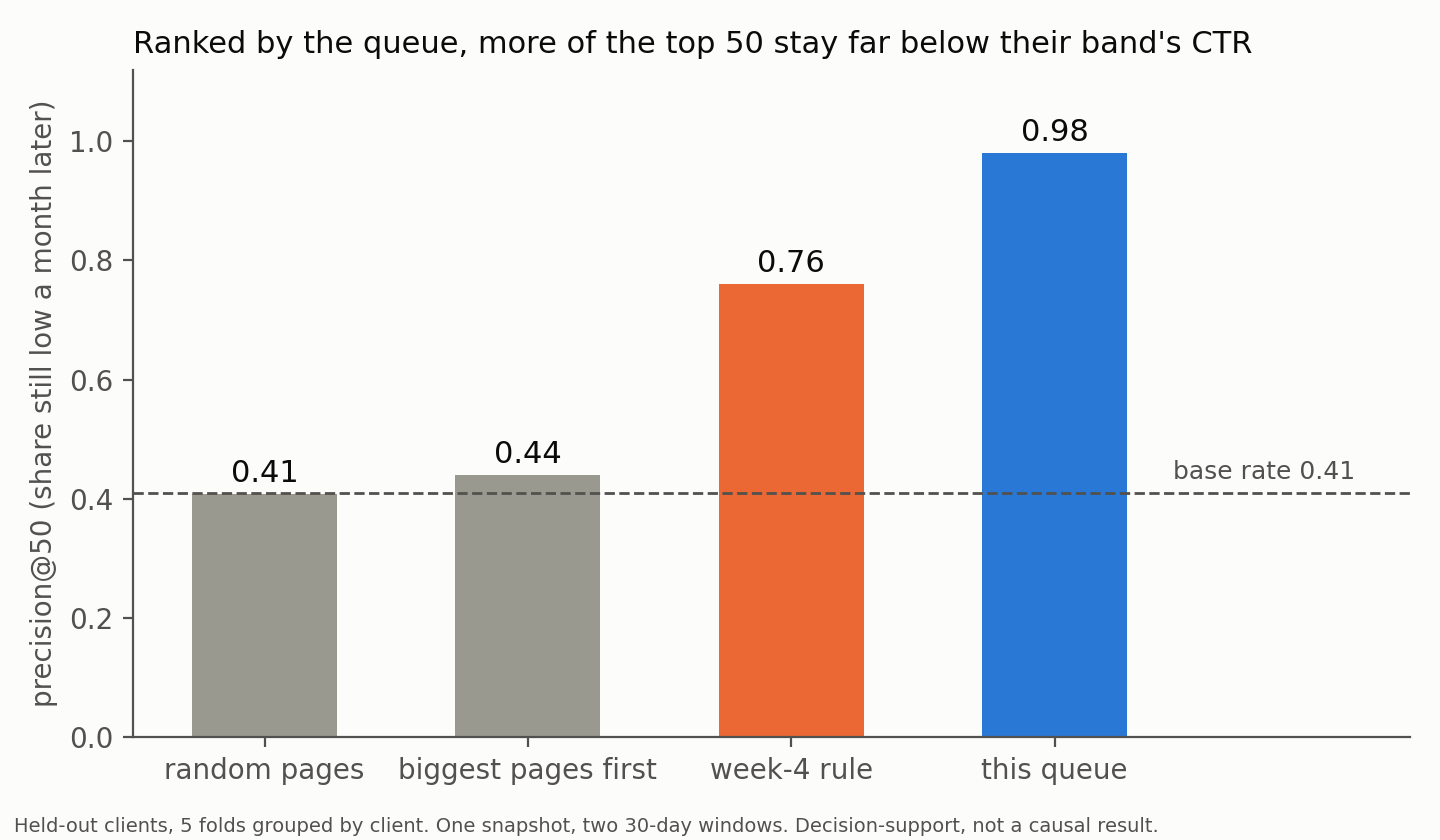

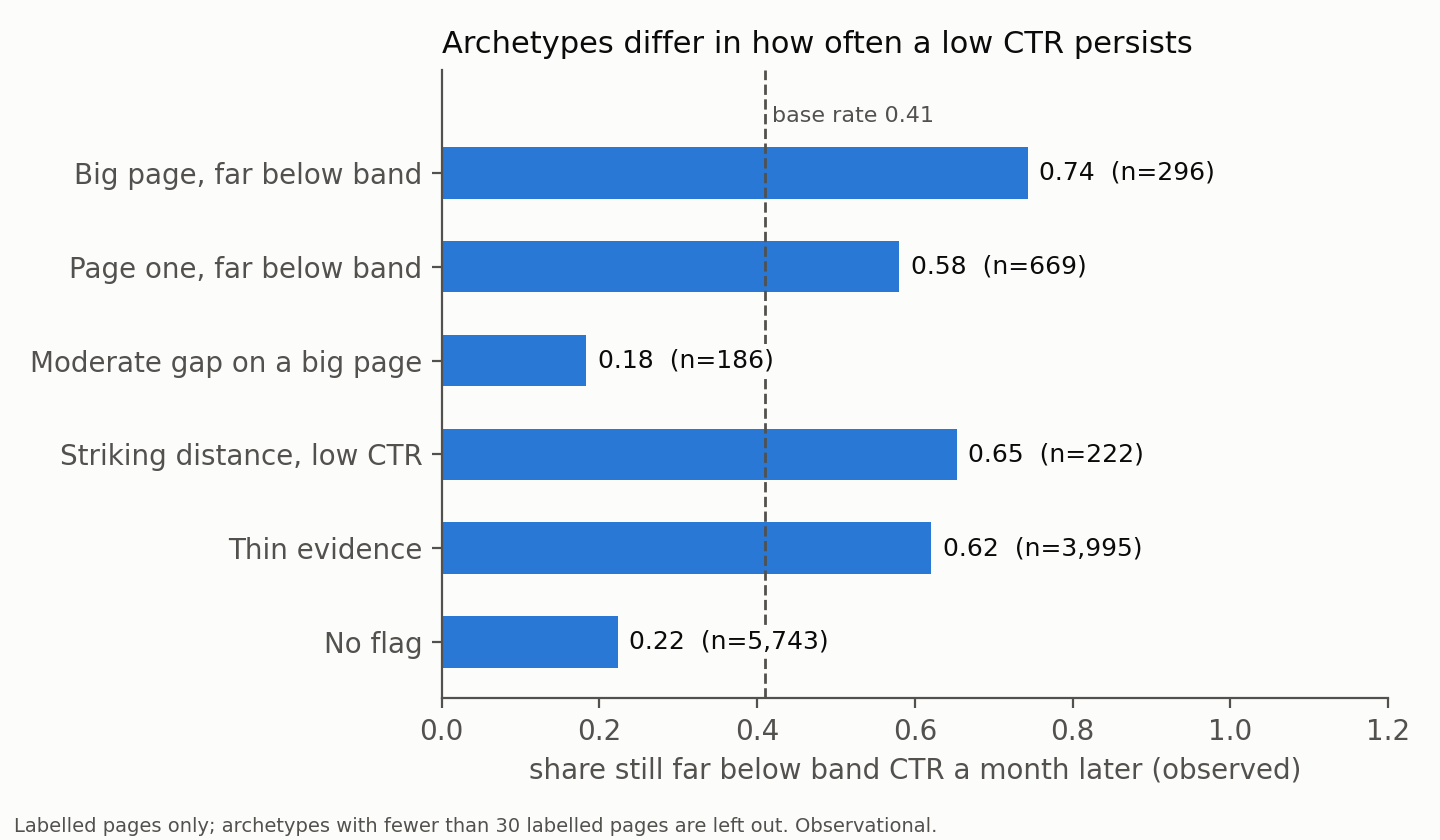

In [12]:
from IPython.display import Image, display
display(Image("work/figures/fig_queue_vs_baselines.png", width=560))
display(Image("work/figures/fig_archetype_low_later.png", width=560))

**Notes for the paper.** Quote numbers from `playbook_metrics.json`, not from memory. State the intended use, the scope guard, the held-out-client design, the base rate, and the limits next to the headline precision. Use *observed*, *measured*, *directional* and *decision-support*; the only action language the data supports is "review these pages first".

## Self-check

Before you submit, confirm each line honestly:

- [ ] Every section above is filled — markdown thinking AND the code that backs it
- [ ] The notebook runs top to bottom with no errors (Runtime → Run all)
- [ ] No client names, URLs, or private queries anywhere
- [ ] My claims use careful words: observed, measured, directional, decision-support
- [ ] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.